In [3]:
#Importación de librerías
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats

In [4]:
#Cargar el modelo multiple_regression
artifacts = joblib.load("../../../models/exp02_ols_no_imc/multiple_regression.joblib")
type(artifacts)

dict

In [5]:
#Explorando las claves del diccionario 
artifacts.keys()

dict_keys(['model', 'features', 'X_train', 'y_train', 'X_test', 'y_test', 'metrics'])

In [6]:
#Alamacenar los valores de las claves en nuestras propias variables
model = artifacts["model"]
X_train = artifacts["X_train"]
y_train = artifacts["y_train"]
y_test = artifacts["y_test"]
X_test = artifacts["X_test"]
metrics = artifacts["metrics"]

In [7]:
#Explorar el modelo (Opcional)
type(model)

sklearn.linear_model._base.LinearRegression

In [8]:
#Realizar predicciones
y_pred = model.predict(X_test)

In [9]:
#Obtener los residuos
residuos = y_test - y_pred
residuos.head(10)

46      1.792875
9       1.575612
206    -5.553688
139     2.262684
60     -1.292220
33      0.050211
297    -3.373055
186    -1.903524
296     1.228180
277    14.038267
Name: PESO (KG), dtype: float64

**ANALISIS DE RESIDUOS**

**1.- Distribución de los residuos**

In [10]:
#Verificar numero de clases
len(residuos.unique())

63

<function matplotlib.pyplot.show(close=None, block=None)>

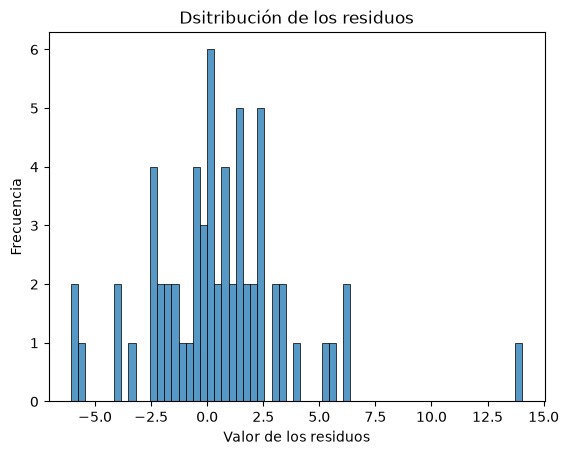

In [11]:
#Graficar histograma de residuos 
sns.histplot(residuos, bins=63)
plt.title("Dsitribución de los residuos")
plt.xlabel("Valor de los residuos")
plt.ylabel("Frecuencia")
plt.savefig("../../../graphics/exp02_ols_no_imc/histograma_residuos.png")
plt.show

Se observa una sobrestimación controlada a diferencia del modelo anterior, sin embargo tambien se observa la presencia de un residuo atipico (outlier) en la sobrestimación.

De forma anticipada se recomienda migrar a un modelo "robusto".

**2.- Residuos contra Valores predichos**

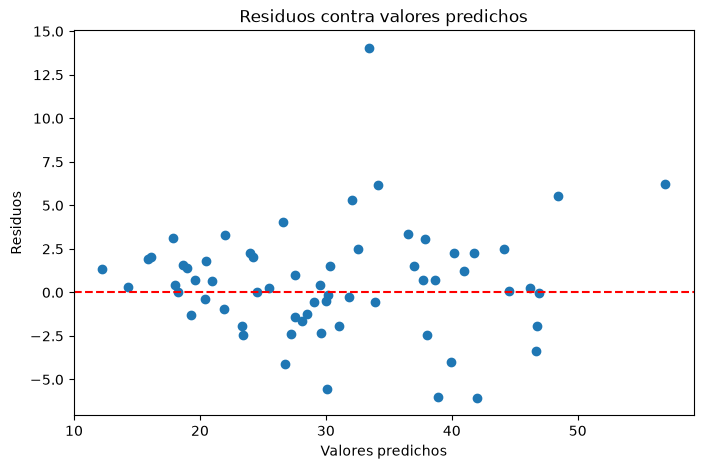

In [12]:
#Scatterplot del peso predicho contra el error

plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuos)
plt.axhline(0, linestyle="--", color="red")

plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos contra valores predichos")
plt.savefig("../../../graphics/exp02_ols_no_imc/residuos_vs_valores_predichos.png")
plt.show()

Se observa que el residuo extremo no se ubica en los valores extremos de y, por el contrario ocupa un valor central, lo que indica que no necesariamente exista ruido en y sino en alguna variable predictora X.

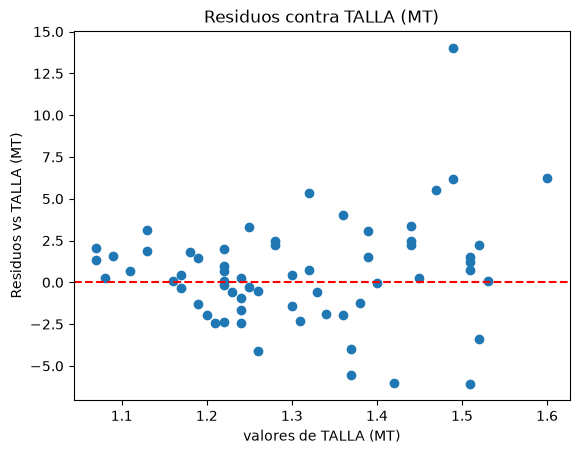

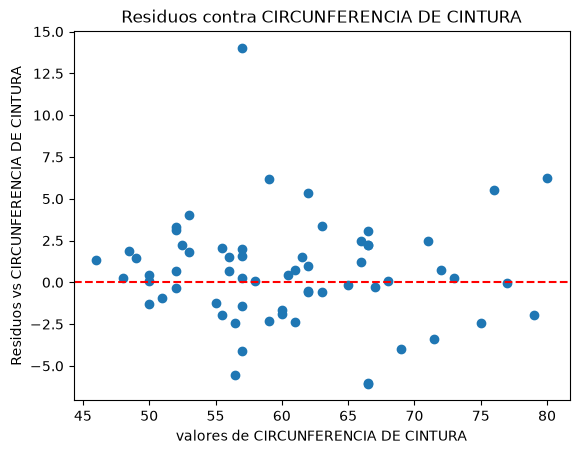

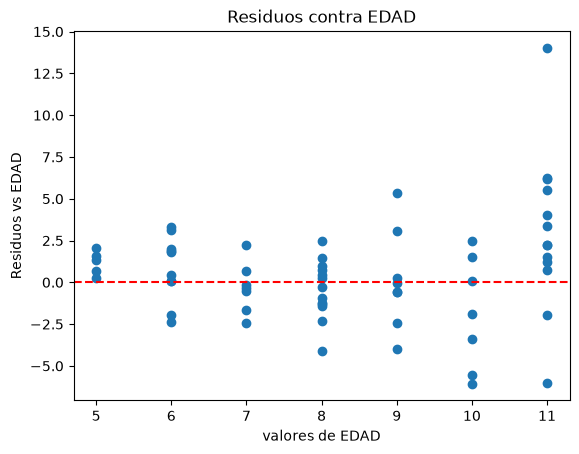

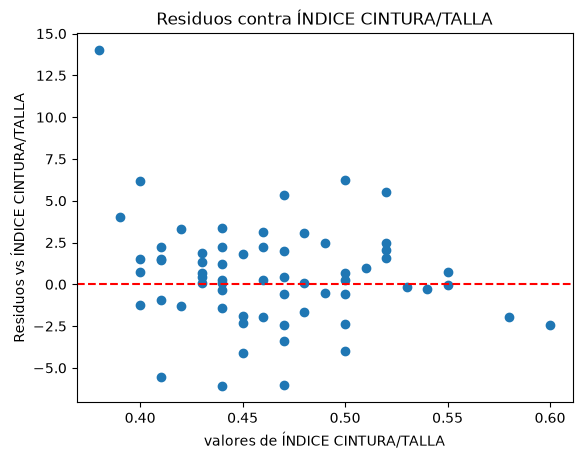

In [ ]:
#Scatterplot de los residuos vs cada variable predictora
for column in X_test.columns:
    plt.scatter(X_test[column], residuos)
    plt.axhline(0, linestyle="--", color="red")
    plt.title(f"Residuos contra {column}")
    plt.ylabel(f"Residuos vs {column}")
    plt.xlabel(f"valores de {column}")
    plt.show()


Revisando el valor residual outlier encontramos que unicamente en una variable predictora es outlier, esto es, en el indice cintura/Talla, despues de confirmado el valor del outlier, se busca migrar a un modelo robusto.

**3.- Grafico Q-Q Plot como una prueba de normalidad**


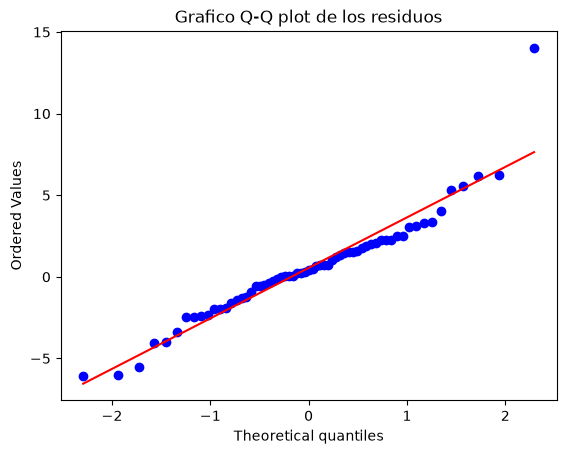

In [15]:
stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Grafico Q-Q plot de los residuos")
plt.savefig("../../../graphics/exp02_ols_no_imc/Q-Q_plot_residual.png")
plt.show()

Se observa en el Q-Q plot que los residuos ahora sí siguen una distribución normal, excepto en el valor outlier el cual es un dato no normalizado.

**Diagnostico General**
De acuerdo a la información de los graficos:
1.- Histograma de la distribución de los residuos
2.- Scatterplot de los valores predichos vs los reeales
3.- Q-Q plot

Determinamos que los residuos siguen una distribución normal, el modelo subestima y sobrestima de forma controlada, sin embargo, se observa la presencia de un residuo outlier demasiado ruidoso.

Sugerencias:
-Probar un modelo robusto.

Tarea: Infografía titulada "Regresion Hubber"